In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv(r"C:\Users\karan\Downloads\WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Convert TotalCharges into numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Handle missing TotalCharges
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Remove duplicate customer records, if any
df = df.drop_duplicates(subset="customerID")

print(df.shape)
print(df.isnull().sum().sum())

(7043, 21)
0


In [3]:
X = df.drop(
    columns=["customerID", "Churn"]
)

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Features:", X.shape)
print("Target:", y.shape)

print(y.value_counts())

Features: (7043, 19)
Target: (7043,)
Churn
0    5174
1    1869
Name: count, dtype: int64


In [4]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "SeniorCitizen"
]

categorical_features = [
    col for col in X.columns
    if col not in numerical_features
]

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [5]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 5634
Testing records: 1409


In [7]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [8]:
y_pred = model.predict(X_test)

y_probability = model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))

print("Recall:", recall_score(y_test, y_pred))

print("F1 Score:", f1_score(y_test, y_pred))

print("ROC AUC:", roc_auc_score(y_test, y_probability))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.7381121362668559
Precision: 0.504302925989673
Recall: 0.7834224598930482
F1 Score: 0.6136125654450262
ROC AUC: 0.8416388953473353

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



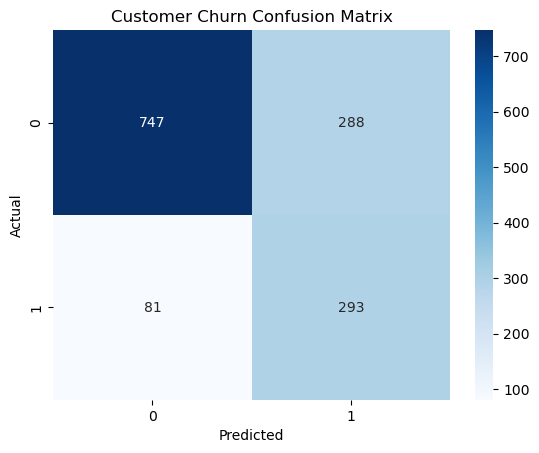

In [9]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Customer Churn Confusion Matrix")

plt.show()

In [10]:
os.makedirs("../model", exist_ok=True)

joblib.dump(
    model,
    "../model/churn_pipeline.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [11]:
%pip install fastapi uvicorn joblib pandas scikit-learn

  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached typing_inspection-0.4.4-py3-none-any.whl.metadata (2.6 kB)
  Using cached annotated_doc-0.0.5-py3-none-any.whl.metadata (6.5 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
Using cached uvicorn-0.54.0-py3-none-any.whl (87 kB)
Using cached annotated_doc-0.0.5-py3-none-any.whl (5.3 kB)
   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
   --------- ------------------------------ 0.5/2.3 MB 2.8 MB/s eta 0:00:01
   ------------------ --------------------- 1.0/2.3 MB 2.5 MB/s eta 0:00:01
   --------------------------- ------------ 1.6/2.3 MB 2.4 MB/s eta 0:00:01
   -------------------------------- ------- 1.8/2.3 MB 2.3 MB/s eta 0:00:01
   ---------------------------------------- 2.3/2.3 MB 2.2 MB/s eta 0:00:00
Using cached typing_extensions-4.16.0-py3-none-any.whl (45 kB)
Using cached typing_inspection-0.4.4-py3-none-any.whl (14 kB)
  Attempting uninstall: typing